# E6: CRNN | 128 Mel bins | không SpecAugment
Nhánh GitHub: `09-E6-crnn-mel128`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [2]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [3]:
EXP_ID = "E6"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'crnn', 'n_mels': 128, 'specaug': False}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [4]:
lr = search_lr(EXP_ID)

train:   0%|          | 0/40 [00:00<?, ?it/s]

E6 {'LR': 0.0003, 'EPOCHS': 40} -> 0.7715


train:   0%|          | 0/40 [00:00<?, ?it/s]

E6 {'LR': 0.001, 'EPOCHS': 40} -> 0.7524


,LR,EPOCHS,val_macro_f1,best_epoch
0,0.0003,40,0.771472,39
1,0.0010,40,0.752435,39


E6: learning rate được chọn = 0.0003


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [5]:
runs, rob = run_exp(EXP_ID, lr)

E6 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E6 | fold 1] acc 0.7575 | macro-F1 0.7413 | lr 0.0003 | epoch tốt nhất 72 | 201s


E6 | fold 2:   0%|          | 0/80 [00:00<?, ?it/s]

[E6 | fold 2] acc 0.7900 | macro-F1 0.7816 | lr 0.0003 | epoch tốt nhất 66 | 200s


E6 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E6 | fold 3] acc 0.7550 | macro-F1 0.7471 | lr 0.0003 | epoch tốt nhất 66 | 200s


E6 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E6 | fold 4] acc 0.7975 | macro-F1 0.7948 | lr 0.0003 | epoch tốt nhất 69 | 200s


E6 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E6 | fold 5] acc 0.7625 | macro-F1 0.7433 | lr 0.0003 | epoch tốt nhất 68 | 201s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.7575,0.7413,0.0003,72,0.7933,200.5248
1,2,0.7900,0.7816,0.0003,66,0.7852,200.4758
2,3,0.7550,0.7471,0.0003,66,0.8207,200.4769
3,4,0.7975,0.7948,0.0003,69,0.7099,200.4842
4,5,0.7625,0.7433,0.0003,68,0.7857,200.5366


E6: Accuracy 77.25 ± 1.98 | Macro-F1 76.16 ± 2.48 | 2,858,194 tham số


,acc,macro_f1
condition,,
Sạch,77.25,76.16
20 dB,60.35,60.74
10 dB,32.05,35.07
0 dB,5.90,5.53


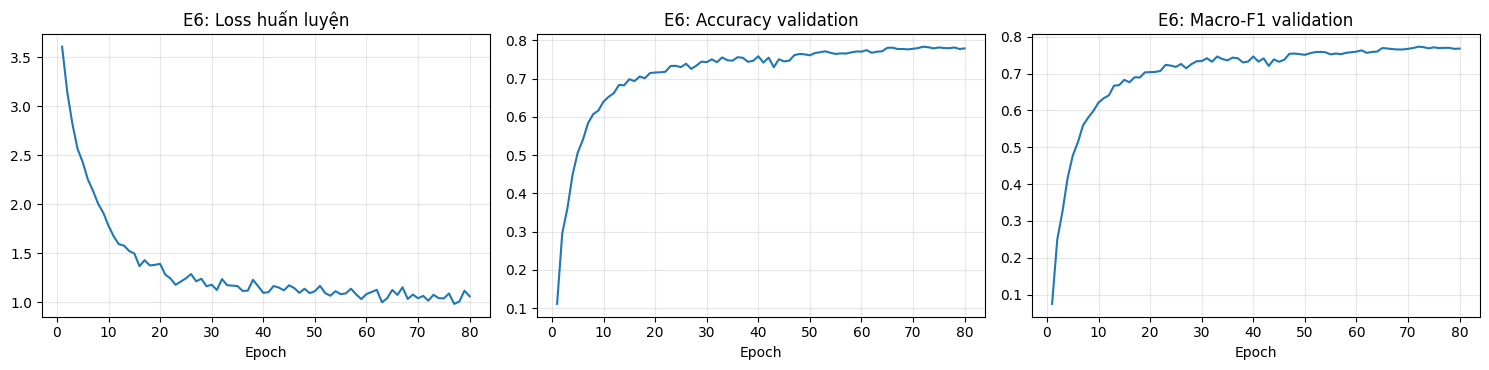

In [6]:
show_exp(EXP_ID)